# Path 3 — strategy screen (Nov 6, 2026)

Strategies: S0a greedy, S0b″ gated noise + hold, S2 stuck timer + yield + hold (v2: blip-tolerant clock),
S1′ amplified averaging (v2: quiet probe; code name S1p), and the v1 variants S2_v1, S1p_v1,
simulated on the lab v09 interface (`src/slider/path3/`). Runs come from `scripts/path3_screen.py` → `results/path3/runs.csv`.
Human inputs (reaction / start delays, consensus times) are lab v09 G-train rounds only; no test runs are used.
The graph split is `data/splits/graph_split.csv`; graph-test is never used.

In [1]:
import json

import numpy as np
import pandas as pd

from slider import config
from slider.path3 import graphs, human, report

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
runs = pd.read_csv(config.PATH3 / "runs.csv")
screen = runs[runs["block"].isin(["screen_A", "screen_B"])]
sweeps = runs[runs["block"].isin(["sweep_A", "sweep_B"])]
raw = runs[runs["block"].isin(["raw_A", "raw_B"])]
order = list(json.loads((config.PATH3 / "screening_set.json").read_text()))
runs.groupby(["block", "strategy"]).size().unstack()

strategy,S0a,S0b,S1p,S1p_v1,S2,S2_v1
block,,,,,,
raw_A,4600.0,4600.0,4600.0,4600.0,4600.0,4600.0
raw_B,1640.0,1640.0,1640.0,1640.0,1640.0,1640.0
screen_A,4600.0,4600.0,4600.0,4600.0,4600.0,4600.0
screen_B,1640.0,1640.0,1640.0,1640.0,1640.0,1640.0
sweep_A,NaN,800.0,800.0,NaN,1600.0,NaN
sweep_B,NaN,800.0,800.0,NaN,1600.0,NaN


## Sanity tests on Hierarchy (fix round, step 4; `scripts/path3_fixtests.py`)

In [2]:
fix = pd.read_csv(config.PATH3 / "fix_tests.csv")
flags = report.sanity(fix)
fix.round(3)

,test,strategy,runs,success_300,pass,median_t,stuck_share_of_idle_ticks,probes,share_sum_zero,q,q_nbr_moved,q_nbr_still,share_nbr_moved,median_wait_s,mean_wait_s
0,2,S0b,200,1.000,True,18.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,S2,200,1.000,True,19.1,0.163,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,S1p,2520,0.057,False,inf,NaN,5974460.0,0.753,0.882,0.724,1.0,0.428,0.1,0.141


## Screening set: 5 human networks + 2 graph-train graphs per (fraught tercile × |λ| tercile) cell

In [3]:
split = graphs.load_split()
split[split["graph"].isin(order) | split["human"].notna()][["graph", "human", "n_edges", "n_fraught", "lam", "cell", "split"]]

,graph,human,n_edges,n_fraught,lam,cell,split
0,G270,Star,6,0,5.000000e-01,0,train
6,G278,Hierarchy,6,4,8.903882e-01,8,train
26,G331,NaN,7,8,8.859264e-01,8,train
43,G353,Ring,7,28,7.489932e-01,8,train
50,G385,NaN,8,0,7.500000e-01,2,train
86,G426,NaN,8,8,7.894860e-01,8,train
87,G427,NaN,8,10,6.666667e-01,7,train
110,G450,CT,8,4,9.166667e-01,8,train
112,G474,NaN,9,0,6.910050e-01,2,train
158,G522,NaN,9,8,6.687875e-01,7,train


## Rankings (per graph and pooled over the screening set; Agreement read as integer %)

Rank: success_300 (high first), then median time (a run without consensus counts as infinite).

In [4]:
rank = report.rankings(screen, flags)
rank.to_csv(config.PATH3 / "rankings.csv", index=False)
rank[rank["graph"] == "pooled"].round(3)

,start,graph,rank,strategy,sanity,runs,success_180,success_300,median_t,frac_time_fraught,yields_per_run,collisions_per_run,consensus,fixed trap,periodic,irregular
138,A,pooled,1,S0b,passed,4600,0.999,1.000,26.50,0.024,27.051,39.910,1.000,0.000,0.000,0.000
139,A,pooled,2,S2_v1,failed sanity test,4600,0.800,0.884,57.75,0.063,0.841,0.027,0.884,0.004,0.000,0.112
140,A,pooled,3,S2,passed,4600,0.776,0.852,56.80,0.038,8.164,1.146,0.852,0.000,0.000,0.148
141,A,pooled,4,S0a,passed,4600,0.771,0.849,58.75,0.069,0.000,0.000,0.849,0.037,0.000,0.115
142,A,pooled,5,S1p,failed sanity test,4600,0.000,0.000,inf,0.000,0.000,0.000,0.000,0.000,0.000,1.000
143,A,pooled,6,S1p_v1,failed sanity test,4600,0.000,0.000,inf,0.000,0.000,0.000,0.000,0.000,0.000,1.000
234,B,pooled,1,S0b,passed,1640,0.994,1.000,28.10,0.214,29.798,46.966,1.000,0.000,0.000,0.000
235,B,pooled,2,S2,passed,1640,0.929,0.959,28.75,0.375,5.376,0.906,0.959,0.000,0.000,0.041
236,B,pooled,3,S2_v1,failed sanity test,1640,0.889,0.945,40.30,0.478,1.055,0.026,0.945,0.014,0.001,0.040
237,B,pooled,4,S0a,passed,1640,0.796,0.837,48.85,0.508,0.000,0.000,0.837,0.124,0.001,0.038


In [5]:
rank[rank["graph"].isin(["Hierarchy", "Full", "Ring", "Star", "CT"])].round(3)

,start,graph,rank,strategy,sanity,runs,success_180,success_300,median_t,frac_time_fraught,yields_per_run,collisions_per_run,consensus,fixed trap,periodic,irregular
0,A,CT,1,S0b,passed,200,1.000,1.000,22.05,0.081,22.270,32.110,1.000,0.000,0.000,0.000
1,A,CT,2,S2,passed,200,1.000,1.000,26.55,0.112,4.095,0.720,1.000,0.000,0.000,0.000
2,A,CT,3,S2_v1,failed sanity test,200,0.770,0.905,29.60,0.277,1.530,0.010,0.905,0.055,0.000,0.040
3,A,CT,4,S0a,passed,200,0.775,0.780,23.65,0.243,0.000,0.000,0.780,0.185,0.000,0.035
4,A,CT,5,S1p,failed sanity test,200,0.000,0.000,inf,0.000,0.000,0.000,0.000,0.000,0.000,1.000
5,A,CT,6,S1p_v1,failed sanity test,200,0.000,0.000,inf,0.000,0.000,0.000,0.000,0.000,0.000,1.000
6,A,Full,1,S0b,passed,200,0.985,1.000,40.10,0.000,39.945,60.630,1.000,0.000,0.000,0.000
7,A,Full,2,S0a,passed,200,0.045,0.110,inf,0.000,0.000,0.000,0.110,0.000,0.000,0.890
8,A,Full,3,S2_v1,failed sanity test,200,0.075,0.105,inf,0.000,0.675,0.005,0.105,0.000,0.000,0.895
9,A,Full,4,S2,passed,200,0.045,0.065,inf,0.000,20.865,2.690,0.065,0.000,0.000,0.935


## Sensitivity: Agreement read unrounded (pooled)

In [6]:
report.rankings(raw, flags).query("graph == 'pooled'").round(3)

,start,graph,rank,strategy,sanity,runs,success_180,success_300,median_t,frac_time_fraught,yields_per_run,collisions_per_run,consensus,fixed trap,periodic,irregular
138,A,pooled,1,S0b,passed,4600,0.998,1.000,27.00,0.023,27.353,40.404,1.000,0.000,0.000,0.000
139,A,pooled,2,S2_v1,failed sanity test,4600,0.793,0.878,58.40,0.066,0.846,0.029,0.878,0.004,0.000,0.118
140,A,pooled,3,S2,passed,4600,0.785,0.858,58.80,0.039,8.157,1.182,0.858,0.000,0.000,0.142
141,A,pooled,4,S0a,passed,4600,0.777,0.854,56.35,0.071,0.000,0.000,0.854,0.036,0.000,0.110
142,A,pooled,5,S1p,failed sanity test,4600,0.000,0.000,inf,0.000,0.000,0.000,0.000,0.000,0.000,1.000
143,A,pooled,6,S1p_v1,failed sanity test,4600,0.000,0.000,inf,0.000,0.000,0.000,0.000,0.000,0.000,1.000
234,B,pooled,1,S0b,passed,1640,0.996,1.000,29.20,0.217,30.835,48.680,1.000,0.000,0.000,0.000
235,B,pooled,2,S2,passed,1640,0.927,0.964,28.45,0.373,5.221,0.869,0.964,0.000,0.000,0.036
236,B,pooled,3,S2_v1,failed sanity test,1640,0.874,0.944,44.10,0.469,1.079,0.015,0.944,0.013,0.001,0.043
237,B,pooled,4,S0a,passed,1640,0.807,0.852,47.80,0.500,0.000,0.000,0.852,0.113,0.001,0.034


## Efficiency gap: human median consensus time ÷ strategy median time (start A)

Only Hierarchy and Full have lab v09 G-train rounds (Star has none in lab v09; Ring and CT are test topologies).

In [7]:
gap = report.efficiency_gap(screen[screen["start"] == "A"], pd.read_csv(human.CONSENSUS))
gap.round(2)

,graph,human_rounds,human_median_t,strategy,strategy_median_t,gap
0,Full,27,65.35,S0a,inf,0.00
1,Full,27,65.35,S0b,40.10,1.63
2,Full,27,65.35,S1p,inf,0.00
3,Full,27,65.35,S1p_v1,inf,0.00
4,Full,27,65.35,S2,inf,0.00
5,Full,27,65.35,S2_v1,inf,0.00
6,Hierarchy,60,34.66,S0a,30.90,1.12
7,Hierarchy,60,34.66,S0b,20.35,1.70
8,Hierarchy,60,34.66,S1p,inf,0.00
9,Hierarchy,60,34.66,S1p_v1,inf,0.00


## Figure 1: Hierarchy sweeps (median time vs ε, H, T, p, κ)

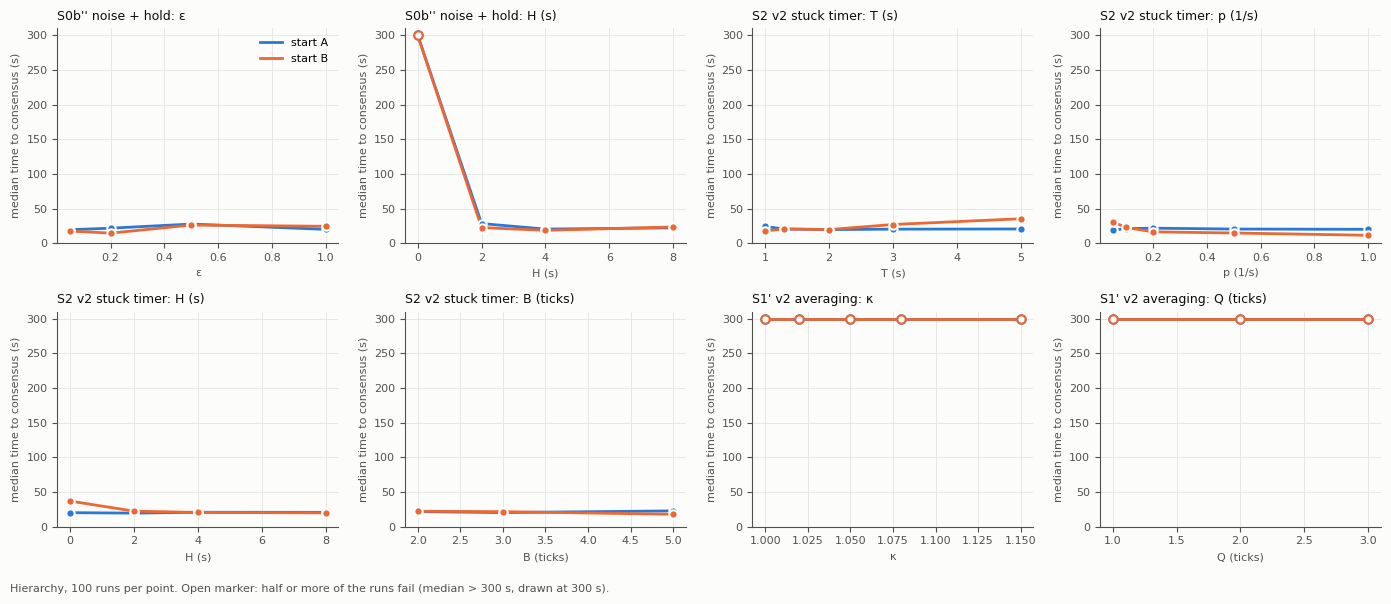

In [8]:
report.sweep_figure(sweeps, config.FIGURES / "path3_sweeps.png");

## Figure 2: strategy × screening graph, median time (start A)

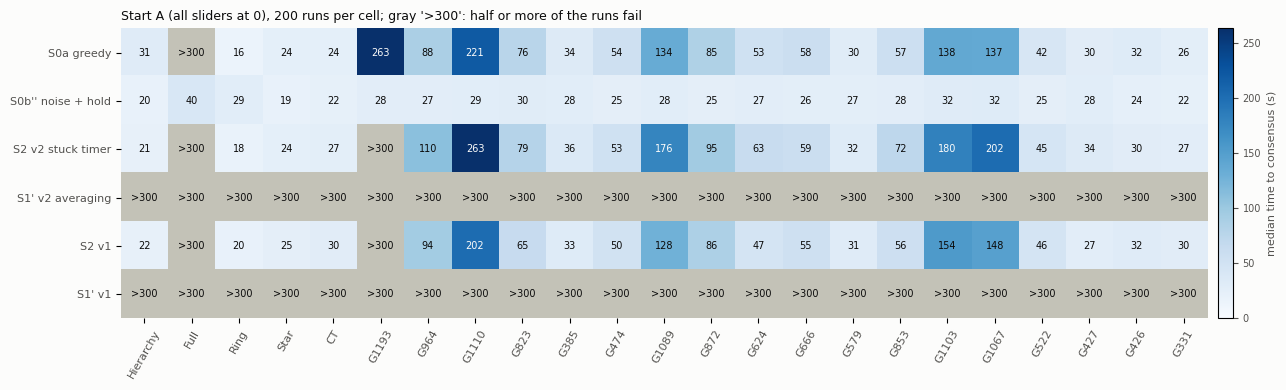

In [9]:
report.heatmap_figure(screen[screen["start"] == "A"], order, config.FIGURES / "path3_heatmap.png");